# Scenario contexts on the toy assets: shocks, curve shapes, rolls, MultiScenario

The gs `01_scenarios_and_contexts` examples, run on pricebt's deterministic toy assets
(`tests/assets/`), so they run anywhere with no market data. The scenario code is gs's own. What
makes it price is each asset config's `scenarios:` section, which maps every scenario type to
a market transform of the toy library (`tests/toylib/scenarios.py`). Your configs do the same with
your library (`docs/v2/SCENARIOS.md`).

1. market data patterns and shocks: rate and vol shocks, delta and vega by shocks;
2. composite scenarios and their order;
3. curve shapes: parallel, steepeners and flatteners, an index curve shift, a curve overlay;
4. `RollFwd`: carry and the lifecycle of swaptions through expiry;
5. `MeasureScenario`: price at a given forward or vol;
6. `MultiScenario`: **terminal payoffs of a straddle and a fly**, and a rate x vol grid.

In [1]:
import sys
from datetime import date

import pandas as pd

for _p in ("src", "tests"):  # the toy library lives under tests/ (run from the repo root)
    if _p not in sys.path:
        sys.path.insert(0, _p)

from pricebt.instrument import IRSwap, IRSwaption
from pricebt.markets import PricingContext
from pricebt.markets.portfolio import Portfolio
from pricebt.risk import (CompositeScenario, CurveOverlay, CurveScenario, IndexCurveShift, IRAnnualImpliedVol, IRDelta,
                          IRFwdRate, IRVegaParallel, MarketDataPattern, MarketDataShock, MarketDataShockBasedScenario,
                          MarketDataShockType, MeasureScenario, MultiScenario, RollFwd)
from pricebt.session import PricebtSession

PricebtSession.use(assets=["tests/assets/toy_usd_swaption.yaml", "tests/assets/toy_usd_irs_full.yaml"])
PricingContext.current = PricingContext(date(2024, 3, 4))

swaption = IRSwaption("Receive", "10y", "USD", expiration_date="1y", strike="ATM", notional_amount=10e6, name="rec 1y10y")
swaption.resolve()
swap = IRSwap("Pay", "30y", "USD", notional_amount=10e6, name="pay 30y")
swap.resolve()
base = pd.Series({"swaption": float(swaption.price()), "swap": float(swap.price())})
base

swaption    305959.042287
swap             0.000000
dtype: float64

## 1. Patterns and shocks (gs 0100, 0102)

A `MarketDataPattern` names market data (`'IR'`, `'IR Vol'`, `'FX'`, ...). A `MarketDataShock`
says how to move it. The toy reads `'IR'` as its zero curve and `'IR Vol'` as its normal vol. A
pattern it does not hold (EUR rates, FX) leaves it alone.

In [2]:
def rate(bp, ccy="USD"):
    return MarketDataShockBasedScenario({MarketDataPattern("IR", ccy): MarketDataShock(MarketDataShockType.Absolute, bp / 1e4)}, name=f"{ccy} {bp:+g}bp")


def vol(bp):
    return MarketDataShockBasedScenario({MarketDataPattern("IR Vol"): MarketDataShock(MarketDataShockType.Absolute, bp / 1e4)}, name=f"vol {bp:+g}bp")


shocked = {}
for s in (rate(50), rate(-50), rate(50, "EUR"), vol(10)):
    with s:
        shocked[repr(s)] = {"swaption": float(swaption.price()), "swap": float(swap.price())}
shock_table = pd.DataFrame(shocked).T - base
shock_table

,swaption,swap
USD +50bp,-165775.537674,848299.698673
USD -50bp,261478.676622,-957812.749890
EUR +50bp,0.000000,0.000000
vol +10bp,31147.172729,0.000000


Risk measures are short-hand for scenarios (gs 010204, 010205): a two-sided 1bp shock recovers
the own-rate delta and the vega.

In [3]:
with rate(1):
    up, f_up = swaption.price(), swaption.calc(IRFwdRate)
with rate(-1):
    dn, f_dn = swaption.price(), swaption.calc(IRFwdRate)
with vol(1):
    v_up = swaption.price()
with vol(-1):
    v_dn = swaption.price()
greeks_by_shocks = pd.DataFrame(
    {"by shocks": [(up - dn) / (f_up - f_dn), (v_up - v_dn) / 2],
     "measure": [float(swaption.calc(IRDelta(aggregation_level="Type"))), float(swaption.calc(IRVegaParallel))]},
    index=["delta per bp of the forward", "vega per bp of vol"],
)
greeks_by_shocks

,by shocks,measure
delta per bp of the forward,-4085.577550,-4085.577550
vega per bp of vol,3114.717273,3114.717273


## 2. Composite scenarios (gs 0103)

Nested `with` blocks apply outermost first. A proportional shock and an absolute one do not
commute, so the order shows.

In [4]:
prop = MarketDataShockBasedScenario({MarketDataPattern("IR", "USD"): MarketDataShock(MarketDataShockType.Proportional, 0.10)}, name="rates x 1.1")
with prop, rate(50):
    a_then_b = swaption.price()
with rate(50), prop:
    b_then_a = swaption.price()
with CompositeScenario([prop, rate(50)]):
    composite = swaption.price()
pd.Series({"x1.1 then +50bp": a_then_b, "+50bp then x1.1": b_then_a, "CompositeScenario([x1.1, +50bp])": composite})

x1.1 then +50bp                     66769.329439
+50bp then x1.1                     60186.696381
CompositeScenario([x1.1, +50bp])    66769.329439
dtype: float64

## 3. Curve shapes (gs 0104, 0107)

`CurveScenario`: `parallel_shift` and `curve_shift` in bp, the curve shift linear between
`tenor_start` and `tenor_end` (years), zero at `pivot_point`. On a 30y payer swap, a bear
steepener (the long end up) gains and a bull flattener (the long end down) loses.

In [5]:
usd = MarketDataPattern("IR", "USD")
shapes = {
    "parallel +10": CurveScenario(usd, parallel_shift=10),
    "bear steepener": CurveScenario(usd, curve_shift=10, tenor_start=15, tenor_end=25, pivot_point=15),
    "bull steepener": CurveScenario(usd, curve_shift=10, tenor_start=15, tenor_end=25, pivot_point=25),
    "bear flattener": CurveScenario(usd, curve_shift=-10, tenor_start=15, tenor_end=25, pivot_point=25),
    "bull flattener": CurveScenario(usd, curve_shift=-10, tenor_start=15, tenor_end=25, pivot_point=15),
    "index shift 5bp + 1bp/y to 10y": IndexCurveShift(usd, annualised_parallel_shift=5, annualised_slope_shift=1, cutoff=10),
}
curve_moves = {}
for label, s in shapes.items():
    with s:
        curve_moves[label] = float(swap.price()) - base["swap"]
dates = [date(2024 + i, 3, 4) for i in range(1, 41)]
dfs = [1.045 ** -((d - date(2024, 3, 4)).days / 365.0) for d in dates]  # a user curve: 4.4% continuously compounded
with CurveOverlay(dates=dates, discount_factors=dfs, denominated="USD", csa_term="USD-SOFR", curve_type="Discount Curve"):
    curve_moves["overlay (user discount factors)"] = float(swap.price()) - base["swap"]
pd.Series(curve_moves, name="swap PV change")

parallel +10                       177953.487217
bear steepener                     129988.928989
bull steepener                     -48580.204226
bear flattener                      48083.482137
bull flattener                    -133625.833336
index shift 5bp + 1bp/y to 10y     259926.810939
overlay (user discount factors)    832607.326654
Name: swap PV change, dtype: float64

## 4. `RollFwd`: carry and lifecycle (gs 0101)

A roll moves the valuation date: functions see the rolled date, so time passes and options
expire. Past expiry an in-the-money swaption is the underlying swap, and an out-of-the-money one
is worth nothing (gs 03 lifecycling notebook).

In [6]:
itm = IRSwaption("Receive", "10y", "USD", expiration_date="1m", strike="ATM+20", notional_amount=10e6, name="ITM")
otm = IRSwaption("Receive", "10y", "USD", expiration_date="1m", strike="ATM-20", notional_amount=10e6, name="OTM")
pair = Portfolio([itm, otm])
pair.resolve()
rolls = [f"{b}b" for b in range(0, 45, 4)]
with MultiScenario([RollFwd(date=r, name=r) for r in rolls]):
    lifecycle = pair.price()
lifecycle_table = lifecycle.to_frame().T  # rows: the MultiScenario members (scenario objects)
lifecycle_table.index = pd.Index(rolls, name="roll")
lifecycle_table

instrument_name,ITM,OTM
roll,,
0b,195013.637815,33174.547667
4b,190346.158413,28437.679744
8b,183046.464329,21033.847094
12b,175454.036213,13337.213431
16b,167958.299050,5737.203697
20b,162635.240178,309.805186
24b,162395.032033,0.000000
28b,162499.483547,0.000000
32b,162604.002244,0.000000


## 5. `MeasureScenario`: price at a given forward or vol (gs 0109)

Per trade: the toy moves each trade's own curve until its forward reads the value, in the
config's unit (bp).

In [7]:
f0 = float(swaption.calc(IRFwdRate))
measure_rows = {}
for label, scenarios in {
    "base": [],
    "forward +25bp": [MeasureScenario(IRFwdRate, f0 + 25)],
    "vol 100bp": [MeasureScenario(IRAnnualImpliedVol, 100.0)],
    "forward +25bp, vol 100bp": [MeasureScenario(IRFwdRate, f0 + 25), MeasureScenario(IRAnnualImpliedVol, 100.0)],
}.items():
    with CompositeScenario(scenarios):
        measure_rows[label] = {"IRFwdRate": float(swaption.calc(IRFwdRate)), "IRAnnualImpliedVol": float(swaption.calc(IRAnnualImpliedVol)), "Price": float(swaption.price())}
pd.DataFrame(measure_rows).T

,IRFwdRate,IRAnnualImpliedVol,Price
base,398.905633,98.230117,305959.042287
forward +25bp,423.905633,98.230117,215012.131137
vol 100bp,398.905633,100.000000,311471.727294
"forward +25bp, vol 100bp",423.905633,100.000000,220273.658341


## 6. `MultiScenario`: terminal payoffs (gs 0108)

Resolve first, roll to expiry, then shock the forward across a grid. Each member's value is the
payoff at expiry on that shocked curve. A straddle gives a V with its point at the strike, and a
fly (+1 payer at K-50, -2 at K, +1 at K+50) gives a tent.

In [8]:
straddle = IRSwaption("Straddle", "10y", "USD", expiration_date="1y", strike="ATM", notional_amount=10e6, name="straddle")
legs = [IRSwaption("Pay", "10y", "USD", expiration_date="1y", strike=k, notional_amount=10e6, name=n) for k, n in (("ATM-50", "K-50"), ("ATM", "K"), ("ATM+50", "K+50"))]
fly = Portfolio([legs[0], legs[1].clone(quantity_=-2), legs[2]], name="fly")
straddle.resolve()
fly.resolve()
expiry = straddle.resolved_terms["expiration_date"]

grid = list(range(-100, 101, 10))
members = [rate(bp) for bp in grid]
with RollFwd(date=expiry):
    with MultiScenario(members):
        straddle_payoff = straddle.price()
        fly_payoff = fly.price().aggregate()
payoffs = pd.DataFrame({"straddle": [straddle_payoff[m] for m in members], "fly": [fly_payoff[m] for m in members]},
                       index=pd.Index(grid, name="rate shock at expiry (bp)"))
payoffs.T

rate shock at expiry (bp),-100,-90,-80,-70,-60,-50,-40,-30,-20,-10,...,10,20,30,40,50,60,70,80,90,100
straddle,885116.066913,792822.189828,701390.604908,610813.001451,521081.149901,432186.901043,344122.185221,256879.011549,170449.467144,84825.716353,...,84035.365370,167287.988234,249765.402825,331475.069863,412424.37728,4.926206e+05,5.720711e+05,6.507829e+05,728763.261525,8.060191e+05
fly,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,70349.133295,155438.731925,239729.256551,323228.431075,...,319812.517643,234477.987698,149932.671653,66169.001557,0.00000,-4.365575e-11,-5.820766e-11,2.910383e-11,0.000000,5.820766e-11


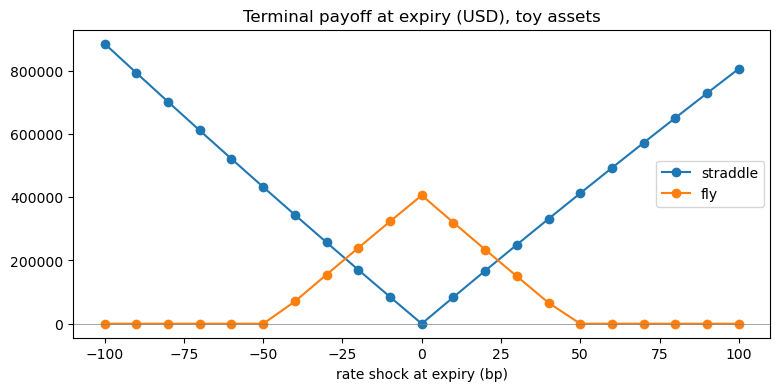

In [9]:
if "ipykernel" in sys.modules:  # plotted in the notebook; a plain script run skips it
    ax = payoffs.plot(figsize=(9, 4), title="Terminal payoff at expiry (USD), toy assets", marker="o")
    ax.axhline(0, color="grey", lw=0.5)

A rate x vol stress of the straddle today: one MultiScenario of composites, one member per pair.

In [10]:
pairs = [(r, v) for r in (-50, -25, 0, 25, 50) for v in (-20, 0, 20)]
cells = [CompositeScenario([rate(r), vol(v)], name=f"{r:+}bp / vol {v:+}bp") for r, v in pairs]
with MultiScenario(cells):
    stress = straddle.price()
stress_grid = pd.DataFrame(index=pd.Index([-50, -25, 0, 25, 50], name="rate bp"), columns=pd.Index([-20, 0, 20], name="vol bp"), dtype=float)
for (r, v), cell in zip(pairs, cells):
    stress_grid.loc[r, v] = float(stress[cell])
stress_grid.round(0)

vol bp,-20,0,20
rate bp,,,
-50,609278.0,717184.0,831651.0
-25,521945.0,643048.0,765961.0
0,487329.0,611918.0,736507.0
25,506192.0,623584.0,742739.0
50,573732.0,674993.0,782474.0
